# Annual sliding-window S&P 500 Sharpe benchmark

Independently refit on **20 full calendar years**, select on the **next 3 validation years**, leave the **next 1 year as a gap**, and evaluate on the **next 3 test years**. Advance by one calendar year over **all eligible local data**, not a fixed window count. Partial boundary years are excluded. Pretraining closes warm up the 60-day emission and lagged ML inputs before the first training target. Existing rule strategies retain their full causal history.

The boundary screen requires all months and observations within seven days of both calendar boundaries; it is not an exchange-calendar missing-session audit. The local data start in July 1962 and end in December 2025: **37 windows**, from training 1963–1982 / validation 1983–1985 / gap 1986 / test 1987–1989 through training 1999–2018 / validation 2019–2021 / gap 2022 / test 2023–2025.

HMM restarts and supervised models are independently refit for each window. Scaling, coefficients, forests, regime names, and strategy choices never use gap/test fitting targets. The gap updates only causal filtering and rolling history. A later window may legitimately train on an earlier window's test dates. No shared module globals are changed.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "notebooks/sp500/sharpe_benchmark_sliding_window.py").exists())
sys.path.insert(0, str(root / "notebooks/sp500"))
import sharpe_benchmark_sliding_window as sliding

prices = sliding.load_prices()
windows = sliding.available_windows(prices)
print(f"Data: {prices.index.min().date()} to {prices.index.max().date()}")
print(f"Eligible annual windows: {len(windows)}")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(windows)

Data: 1962-07-02 to 2025-12-31
Eligible annual windows: 37


,training_start,training_end,validation_start,validation_end,gap_start,gap_end,test_start,test_end
window,,,,,,,,
1963,1963-01-01,1982-12-31,1983-01-01,1985-12-31,1986-01-01,1986-12-31,1987-01-01,1989-12-31
1964,1964-01-01,1983-12-31,1984-01-01,1986-12-31,1987-01-01,1987-12-31,1988-01-01,1990-12-31
1965,1965-01-01,1984-12-31,1985-01-01,1987-12-31,1988-01-01,1988-12-31,1989-01-01,1991-12-31
1966,1966-01-01,1985-12-31,1986-01-01,1988-12-31,1989-01-01,1989-12-31,1990-01-01,1992-12-31
1967,1967-01-01,1986-12-31,1987-01-01,1989-12-31,1990-01-01,1990-12-31,1991-01-01,1993-12-31
1968,1968-01-01,1987-12-31,1988-01-01,1990-12-31,1991-01-01,1991-12-31,1992-01-01,1994-12-31
1969,1969-01-01,1988-12-31,1989-01-01,1991-12-31,1992-01-01,1992-12-31,1993-01-01,1995-12-31
1970,1970-01-01,1989-12-31,1990-01-01,1992-12-31,1993-01-01,1993-12-31,1994-01-01,1996-12-31
1971,1971-01-01,1990-12-31,1991-01-01,1993-12-31,1994-01-01,1994-12-31,1995-01-01,1997-12-31


## Run all independent fits

This cell can be expensive: ten HMM restarts and three supervised fits per window. Run the notebook to regenerate all displayed outputs. All eight original candidates, the validation-selected single strategy (`dev_best_single`), and executable `co_rotation` are retained. Selection maximizes finite validation net Sharpe, with the original 20-regime-day guard, buy-and-hold fallback, and deterministic row-order tie breaking.

Costs are **5 bps per unit of actual turnover**, including entry from cash at each validation/test boundary. Switching strategies incurs costs only for actual position changes. Signals use closes through $t-1$; same-close fills are idealized. PnL is approximate log PnL, cash earns zero, and financing/borrow costs are omitted. Conditional Sharpes use daily 252 scaling, not elapsed regime time.

In [2]:
report = sliding.run_benchmark(prices, progress=True)

Window 1/37: 1963
Window 2/37: 1964
Window 3/37: 1965
Window 4/37: 1966
Window 5/37: 1967
Window 6/37: 1968
Window 7/37: 1969
Window 8/37: 1970
Window 9/37: 1971
Window 10/37: 1972
Window 11/37: 1973
Window 12/37: 1974
Window 13/37: 1975
Window 14/37: 1976
Window 15/37: 1977
Window 16/37: 1978
Window 17/37: 1979
Window 18/37: 1980
Window 19/37: 1981
Window 20/37: 1982
Window 21/37: 1983
Window 22/37: 1984
Window 23/37: 1985
Window 24/37: 1986
Window 25/37: 1987
Window 26/37: 1988
Window 27/37: 1989
Window 28/37: 1990
Window 29/37: 1991
Window 30/37: 1992
Window 31/37: 1993
Window 32/37: 1994
Window 33/37: 1995
Window 34/37: 1996
Window 35/37: 1997
Window 36/37: 1998
Window 37/37: 1999


Model is not converging.  Current: 65781.46217222337 is not greater than 65781.65213943095. Delta is -0.18996720758150332
Model is not converging.  Current: 65127.85745342667 is not greater than 65128.76499113271. Delta is -0.9075377060362371
Model is not converging.  Current: 65592.40052921925 is not greater than 65592.40909245088. Delta is -0.008563231633161195
Model is not converging.  Current: 64941.43366853857 is not greater than 64942.51262042817. Delta is -1.0789518895981018
Model is not converging.  Current: 65458.87691250207 is not greater than 65458.891344883035. Delta is -0.01443238096544519
Model is not converging.  Current: 65487.205756852 is not greater than 65487.26076915925. Delta is -0.05501230724621564
Model is not converging.  Current: 65462.11713489081 is not greater than 65500.78234434066. Delta is -38.6652094498495
Model is not converging.  Current: 66788.93157601859 is not greater than 66789.34085908858. Delta is -0.4092830699955812
Model is not converging.  Curr

## Full per-window evidence and performance

Display every window's boundaries, training regime moments/transitions, RF training accuracy, validation counts/Sharpes and frozen choices, test counts/regime Sharpes, and **all numeric performance metrics**. Daily test positions, PnL, labels, and split returns remain accessible in `report["results"][window]`.

Drawdown includes the initial \$1 peak; Calmar uses that same corrected drawdown. Reported annual turnover includes initial entry, consistent with charged costs (the original package summary omits entry). Other metric definitions remain unchanged: annual return is annualized mean log PnL, and Sortino uses negative-day standard deviation.

In [3]:
with pd.option_context("display.max_rows", None, "display.max_columns", None,
                       "display.width", 180):
    for window, result in report["results"].items():
        print(f"\nWINDOW {window}")
        display(pd.Series(result["bounds"], name="calendar boundaries"))
        for key in ("moments", "transitions", "fit_diagnostics", "train_accuracy",
                    "validation_counts", "validation_table", "rotation",
                    "best_single", "test_counts", "test_table", "summary"):
            print(key)
            display(result[key])


WINDOW 1963
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_table
rotation
best_single
test_counts
test_table
summary

WINDOW 1964
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_table
rotation
best_single
test_counts
test_table
summary

WINDOW 1965
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_table
rotation
best_single
test_counts
test_table
summary

WINDOW 1966
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_table
rotation
best_single
test_counts
test_table
summary

WINDOW 1967
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_table
rotation
best_single
test_counts
test_table
summary

WINDOW 1968
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_table
rotation
best_single
test_counts
test_table
summary

WINDOW 1969
moments
transitions
fit_diagnostics
train_accuracy
validation_counts
validation_t

training_start      1963-01-01
training_end        1982-12-31
validation_start    1983-01-01
validation_end      1985-12-31
gap_start           1986-01-01
gap_end             1986-12-31
test_start          1987-01-01
test_end            1989-12-31
Name: calendar boundaries, dtype: object

,mean_r_%day,sd_r_%day,mean_sigma_%day,regime
0,0.072405,0.530597,0.492468,bull
1,-0.009945,0.751842,0.739687,sideways
2,-0.027055,1.303082,1.127364,bear


array([[9.75148668e-001, 2.48513322e-002, 5.47918012e-051],
       [1.98320860e-002, 9.66376076e-001, 1.37918383e-002],
       [4.18362091e-112, 3.00423834e-002, 9.69957617e-001]])

{'iterations': 53,
 'max_iter_reached': False,
 'last_log_likelihood_delta': 0.0007444895163644105}

0.5842629482071713

... (435 outputs left out)

'logistic_up'

regime
bear         65
sideways    133
bull        554
test_all    752
Name: count, dtype: int64

,bear,sideways,bull,test_all
buy_and_hold,3.384909,0.606781,1.126671,1.288703
ma_50_200,1.304901,-0.112508,1.126671,0.843680
vol_target_60,3.101371,0.734507,0.991772,1.113849
tsmom_126,-3.465878,1.942454,0.979740,0.511747
mean_rev_z20,2.299118,-0.410633,0.183217,0.392543
logistic_up,2.968210,-0.416254,0.211395,0.496120
ridge_return,2.381344,-0.797078,-1.146549,-0.016499
random_forest,2.246157,0.846735,0.190470,0.612491
dev_best_single,2.968210,-0.416254,0.211395,0.496120
co_rotation,2.358978,0.596370,1.126671,0.985289


,years,total_return,ann_return,ann_volatility,sharpe,sortino,max_drawdown,calmar,hit_rate,exposure,turnover_per_year
buy_and_hold,2.984127,0.782023,0.193607,0.150234,1.288703,1.703137,-0.189022,1.024259,0.563830,1.000000,0.335106
vol_target_60,2.984127,0.686542,0.175153,0.157251,1.113849,1.436933,-0.179002,0.978501,0.563830,1.137736,3.654650
co_rotation,2.984127,0.471716,0.129495,0.131428,0.985289,1.186871,-0.176442,0.733923,0.542553,0.920670,2.828665
ma_50_200,2.984127,0.426342,0.119001,0.141050,0.843680,1.039485,-0.189022,0.629560,0.502660,0.900266,1.005319
random_forest,2.984127,0.026061,0.008621,0.014076,0.612491,0.760128,-0.016832,0.512208,0.506649,0.071891,12.160737
tsmom_126,2.984127,0.258780,0.077122,0.150704,0.511747,0.644954,-0.193617,0.398323,0.542553,1.000000,15.079787
logistic_up,2.984127,0.027059,0.008947,0.018034,0.496120,0.549941,-0.025072,0.356848,0.506649,0.066300,10.461173
dev_best_single,2.984127,0.027059,0.008947,0.018034,0.496120,0.549941,-0.025072,0.356848,0.506649,0.066300,10.461173
mean_rev_z20,2.984127,0.114240,0.036249,0.092345,0.392543,0.245512,-0.117819,0.307670,0.073138,0.140957,18.095745
ridge_return,2.984127,-0.000934,-0.000313,0.018976,-0.016499,-0.020228,-0.032668,-0.009583,0.386968,0.042602,13.498595


## Equal-window summaries and selection frequencies

Every numeric performance column and every validation/test regime Sharpe column receives **mean, sample standard deviation ($ddof=1$), and finite-window count**. Undefined/nonfinite observations are excluded per cell, not replaced with zero. Counts can differ; a standard deviation needs two finite observations. All windows have equal weight, not weights proportional to trading days or regime occupancy. Selection frequencies include zero-count candidates and fallback selections.

**Overlapping three-year tests are not independent. These means are not pooled-portfolio performance**, and the standard deviations are not standard errors or confidence intervals. There is no concatenated or stitched portfolio: overlapping dates occur in multiple separately refitted experiments. Validation winners are selection evidence, not independent confirmation. Do not retune choices on these tests.

In [4]:
with pd.option_context("display.max_rows", None, "display.max_columns", None,
                       "display.width", 200):
    for key in ("summary", "validation_table", "test_table", "selections",
                "selection_counts", "selection_frequencies"):
        print(key)
        display(report[key])

summary
validation_table
test_table
selections
selection_counts
selection_frequencies


years                 total_return                 ann_return                 ann_volatility                    sharpe                   sortino                 max_drawdown  \
                     mean       std count         mean       std count       mean       std count           mean       std count      mean       std count      mean       std count         mean   
strategy                                                                                                                                                                                            
vol_target_60    2.999142  0.009027    37     0.331866  0.341636    37   0.084661  0.087210    37       0.154009  0.010366    37  0.561804  0.577172    37  0.732449  0.789022    37    -0.207366   
co_rotation      2.999142  0.009027    37     0.222351  0.212794    37   0.062460  0.054366    37       0.143189  0.059174    37  0.494238  0.388165    37  0.581022  0.531639    37    -0.185363   
buy_and_hold     2.999142  0.009027    37     0.333751  0.346587    37   0.084032  0.093053    37       0.172773  0.057365    37  0.608531  0.574122    37  0.808854  0.790257    37    -0.238190   
tsmom_126        2.999142  0.009027    37     0.207615  0.295131    37   0.053831  0.077692    37       0.172872  0.057280    37  0.322207  0.499686    37  0.442350  0.680225    37    -0.219021   
ma_50_200        2.999142  0.009027    37     0.269300  0.232545    37   0.074715  0.055290    37       0.127991  0.036881    37  0.607377  0.425126    37  0.718635  0.556341    37    -0.165065   
dev_best_single  2.999142  0.009027    37     0.125493  0.225318    37   0.032617  0.068862    37       0.123634  0.067742    37  0.336096  0.485456    37  0.402646  0.655314    37    -0.175513   
ridge_return     2.999142  0.009027    37     0.006565  0.083437    37   0.001153  0.025794    37       0.028438  0.029096    37 -0.138859  0.602482    37 -0.105112  0.856378    37    -0.047091   
random_forest    2.999142  0.009027    37     0.004497  0.026027    37   0.001386  0.008629    37       0.015936  0.006434    37  0.103832  0.546362    37  0.106021  0.734416    37    -0.029683   
logistic_up      2.999142  0.009027    37     0.017349  0.048964    37   0.005374  0.015450    37       0.023022  0.020391    37  0.156555  0.567471    37  0.220747  0.770127    37    -0.034115   
mean_rev_z20     2.999142  0.009027    37     0.087010  0.106206    37   0.026215  0.033212    37       0.107764  0.047524    37  0.327360  0.361599    37  0.215456  0.231883    37    -0.149050   

                                   calmar                  hit_rate                  exposure                 turnover_per_year                   
                      std count      mean       std count      mean       std count      mean       std count              mean        std count  
strategy                                                                                                                                          
vol_target_60    0.082013    37  0.581348  0.600941    37  0.537420  0.026054    37  1.078591  0.218690    37          2.964079   0.611189    37  
co_rotation      0.106859    37  0.459342  0.419159    37  0.416364  0.147892    37  0.684196  0.321646    37         14.649788  12.018720    37  
buy_and_hold     0.138262    37  0.612779  0.603507    37  0.537742  0.026039    37  1.000000  0.000000    37          0.333432   0.001004    37  
tsmom_126        0.081709    37  0.341887  0.509886    37  0.524367  0.018085    37  1.000000  0.000000    37         13.021976   5.675855    37  
ma_50_200        0.076465    37  0.564409  0.484469    37  0.411606  0.104625    37  0.756600  0.189570    37          1.153436   0.419963    37  
dev_best_single  0.129865    37  0.344218  0.468790    37  0.438111  0.159610    37  0.661857  0.416099    37          8.595255  11.781703    37  
ridge_return     0.034810    37  0.098811  0.581530    37  0.453352  0.037136    37  0.072302  0.043765    37         21.900376  17.483

bear                  sideways                      bull                   dev_all                
                   mean       std count      mean       std count      mean       std count      mean       std count
strategy                                                                                                             
buy_and_hold   1.263266  1.744073    21  0.747136  1.443217    35  0.470094  1.309080    37  0.628198  0.568558    37
ma_50_200      1.209918  1.459826    18  0.921177  1.385313    35  0.374470  1.260943    37  0.627381  0.434295    37
vol_target_60  1.240127  1.924824    21  0.737570  1.415492    35  0.424571  1.329328    37  0.589735  0.577289    37
tsmom_126     -0.212807  0.959653    21  0.773690  1.247731    35  0.152768  1.611171    37  0.364369  0.511091    37
mean_rev_z20   1.239807  1.842852    21  0.432671  1.220386    35  0.080954  0.968075    37  0.316291  0.366748    37
logistic_up    0.955039  1.347763    21  0.415495  1.735436    35 -0.183187  1.475962    37  0.379526  0.503734    37
ridge_return   0.517029  1.449452    21 -0.095211  1.708376    35 -0.703135  1.646798    37  0.074422  0.494872    37
random_forest  0.910851  1.371266    21  0.143992  1.524450    35 -0.226404  1.330478    37  0.198996  0.596253    37

bear                  sideways                      bull                  test_all                
                     mean       std count      mean       std count      mean       std count      mean       std count
strategy                                                                                                               
buy_and_hold     0.987808  1.430774    25  1.111683  1.702758    36  0.116880  1.643764    37  0.608531  0.574122    37
ma_50_200        0.822800  1.510075    20  1.261583  1.621422    36  0.132741  1.264294    37  0.607377  0.425126    37
vol_target_60    0.812352  1.469950    25  1.115313  1.671359    36  0.079250  1.600267    37  0.561804  0.577172    37
tsmom_126       -0.186479  1.386685    25  0.942607  1.374802    36 -0.251947  2.097100    37  0.322207  0.499686    37
mean_rev_z20     0.706444  1.245984    25  0.712875  1.256054    36  0.075187  1.037783    35  0.327360  0.361599    37
logistic_up      0.785783  1.368799    25  0.201058  2.288104    36 -0.654451  1.995830    37  0.156555  0.567471    37
ridge_return     0.465873  1.590181    25 -0.231499  2.205878    36 -0.957687  1.504717    37 -0.138859  0.602482    37
random_forest    0.570866  0.914272    25  0.309683  1.749900    36 -0.404626  1.513977    37  0.103832  0.546362    37
dev_best_single  0.853071  1.528087    24  0.741749  1.451034    36 -0.196649  1.579929    37  0.336096  0.485456    37
co_rotation      0.966640  1.350386    25  0.390466  2.115070    36 -0.058566  1.632616    37  0.494238  0.388165    37

,bear,sideways,bull,best_single
window,,,,
1963,vol_target_60,ma_50_200,tsmom_126,ma_50_200
1964,buy_and_hold,random_forest,tsmom_126,buy_and_hold
1965,ridge_return,random_forest,vol_target_60,random_forest
1966,ridge_return,ridge_return,buy_and_hold,ridge_return
1967,ridge_return,vol_target_60,buy_and_hold,vol_target_60
1968,vol_target_60,ridge_return,buy_and_hold,buy_and_hold
1969,buy_and_hold,logistic_up,buy_and_hold,buy_and_hold
1970,buy_and_hold,logistic_up,buy_and_hold,buy_and_hold
1971,buy_and_hold,buy_and_hold,mean_rev_z20,mean_rev_z20


,bear,sideways,bull,best_single
strategy,,,,
buy_and_hold,17,5,15,11
ma_50_200,1,6,1,5
vol_target_60,2,1,5,5
tsmom_126,2,12,3,3
mean_rev_z20,4,4,11,6
logistic_up,4,3,2,5
ridge_return,5,3,0,1
random_forest,2,3,0,1


,bear,sideways,bull,best_single
strategy,,,,
buy_and_hold,0.459459,0.135135,0.405405,0.297297
ma_50_200,0.027027,0.162162,0.027027,0.135135
vol_target_60,0.054054,0.027027,0.135135,0.135135
tsmom_126,0.054054,0.324324,0.081081,0.081081
mean_rev_z20,0.108108,0.108108,0.297297,0.162162
logistic_up,0.108108,0.081081,0.054054,0.135135
ridge_return,0.135135,0.081081,0.000000,0.027027
random_forest,0.054054,0.081081,0.000000,0.027027


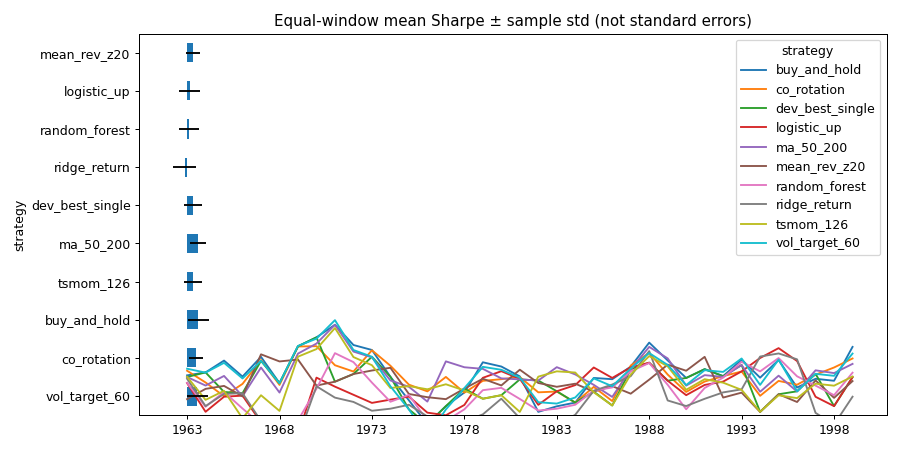

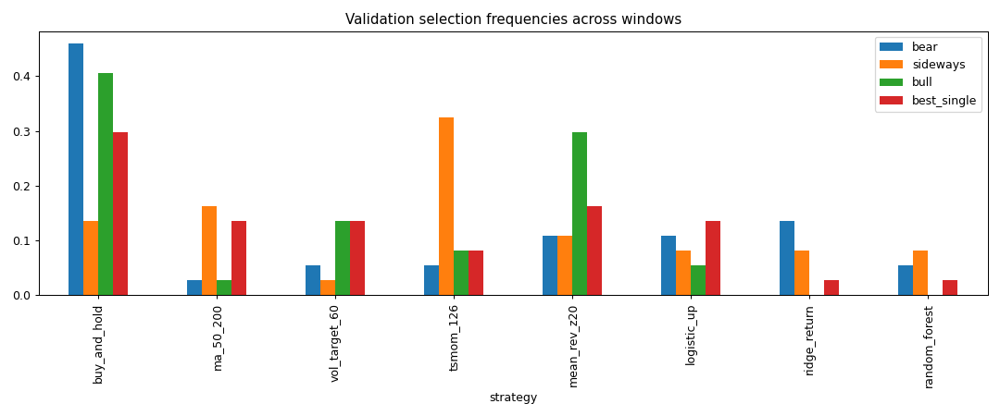

In [5]:
sliding.plot_aggregate(report)
plt.show()

## Per-window plots

Show both causal regime histories and each separate test equity curve for every window. No averaging or stitching of equity curves is performed.

Window 1963
Window 1964
Window 1965
Window 1966
Window 1967
Window 1968
Window 1969
Window 1970
Window 1971
Window 1972
Window 1973
Window 1974
Window 1975
Window 1976
Window 1977
Window 1978
Window 1979
Window 1980
Window 1981
Window 1982
Window 1983
Window 1984
Window 1985
Window 1986
Window 1987
Window 1988
Window 1989
Window 1990
Window 1991
Window 1992
Window 1993
Window 1994
Window 1995
Window 1996
Window 1997
Window 1998
Window 1999


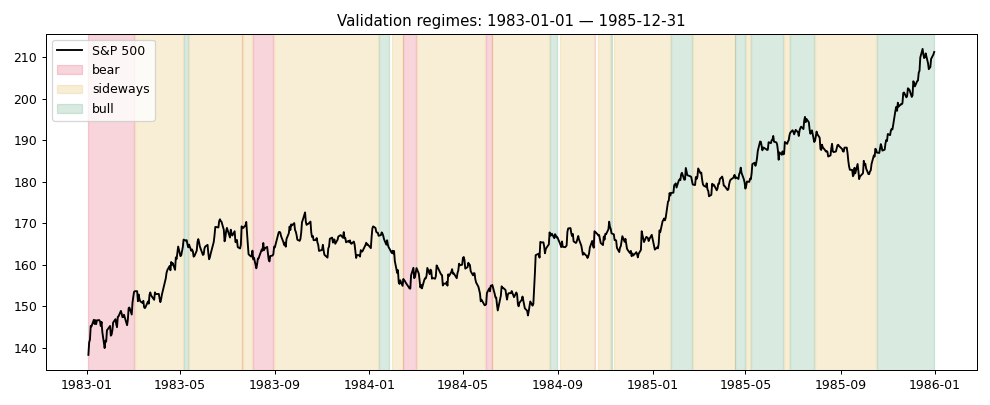

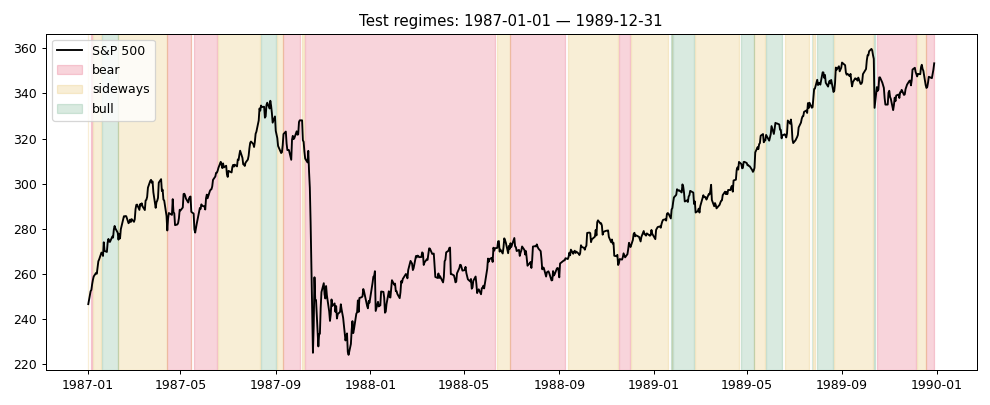

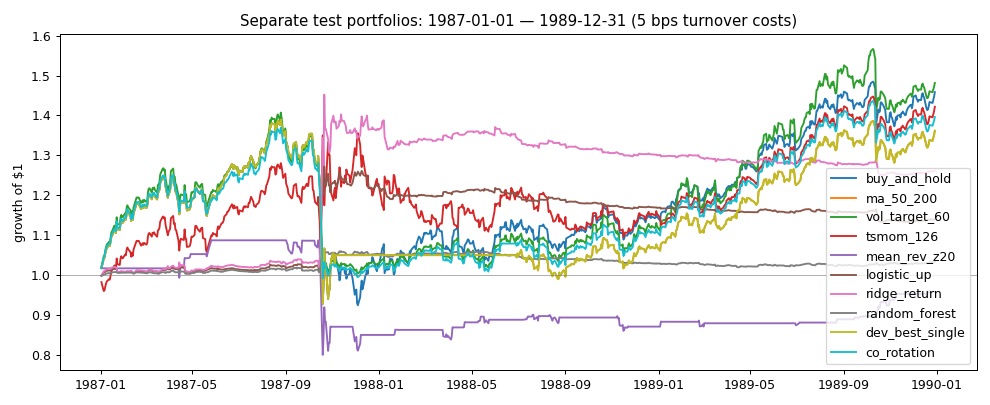

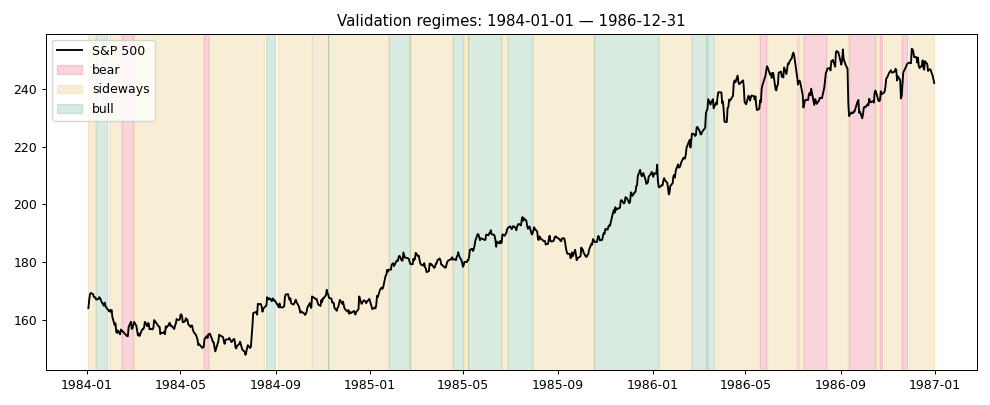

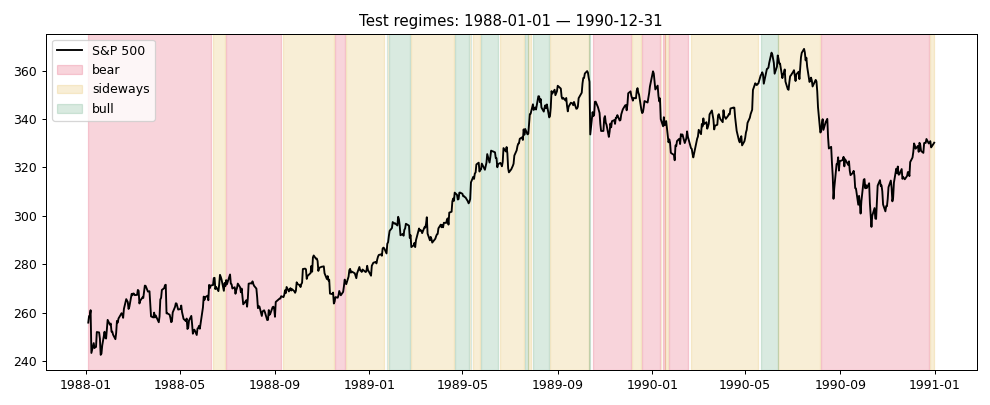

...

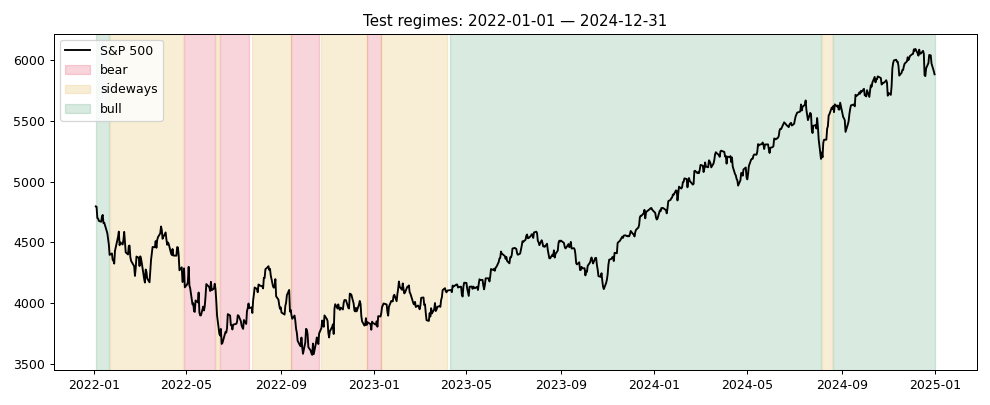

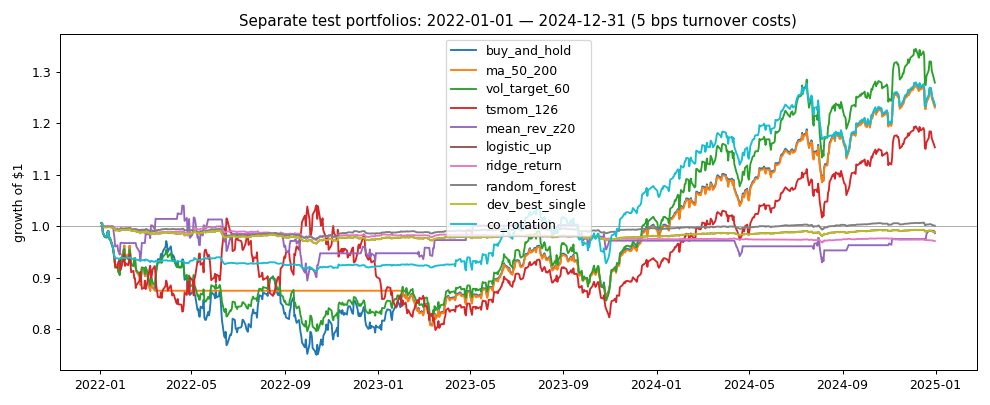

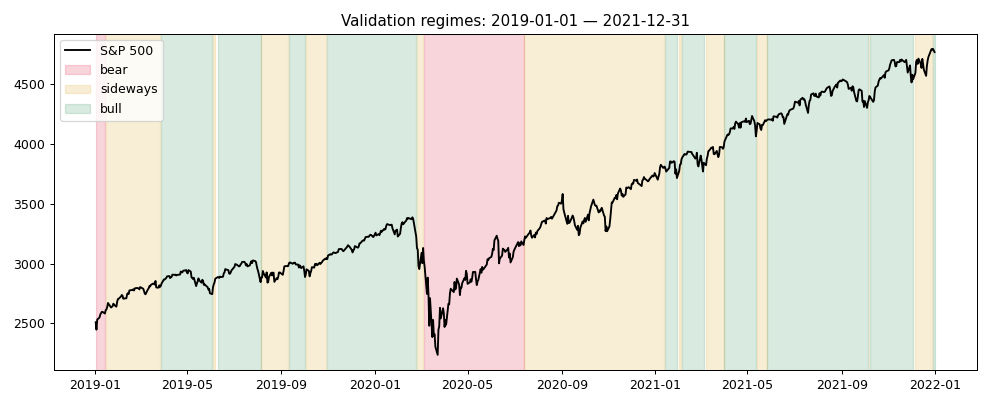

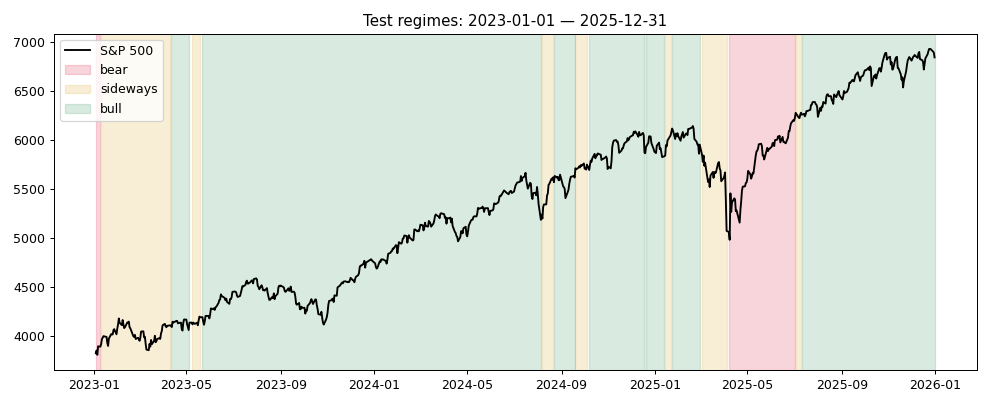

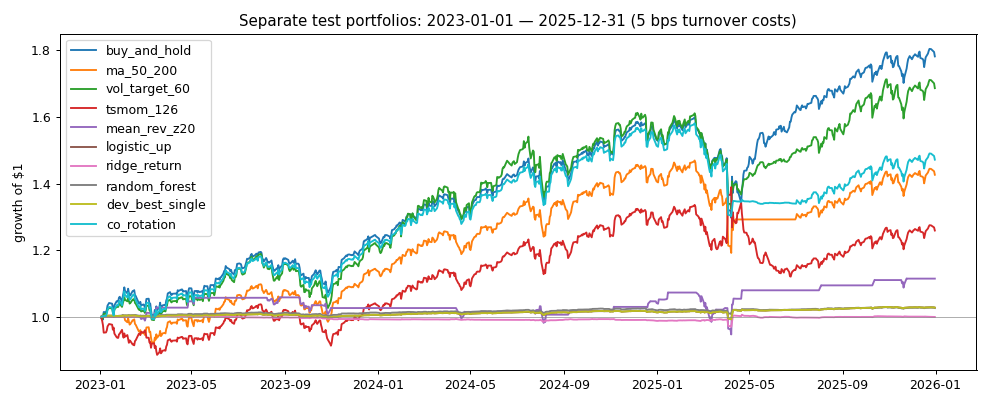

In [6]:
for window, result in report["results"].items():
    print(f"Window {window}")
    sliding.plot_window(result)
    plt.show()
    plt.close("all")